> **Research demo:** the notebook indexes 159 real cases but only demonstrates preprocessing and checkpoint inference on one case. It does not train or evaluate on a patient-held-out cohort. The interactive PNG path was removed because repeating one 2D slice cannot represent a 3D patient volume.

# 3D DCE-MRI Breast Cancer Deep Learning Pipeline

This notebook executes the complete end-to-end deep learning workflow on the real **I-SPY1 DCE-MRI** dataset (`.nii.gz` volumetric MRI files) using **100% pure Deep Learning** (PyTorch & MONAI). No classical ML models or synthetic/dummy data are used.

### Pipeline Execution Sequence:
1. **Data Loading** — Ingest real patient NIfTI volumes ($T_0, T_1, \text{Mask}$) and clinical metadata from `BreastDCEDL_spy1`
2. **Preprocessing** — N4 bias correction, 1.0mm³ isotropic resampling, and peak subtraction volume $I_{\text{sub}} = I_{\text{post}} - I_{\text{pre}}$
3. **Segmentation** — MONAI 3D Residual UNet for volumetric tumor lesion segmentation
4. **Feature Extraction** — Deep latent volumetric feature extraction from the 3D neural network
5. **Testing** — Interactive testing where the user prompts/provides an image as PNG (`.png`)
6. **pCR Prediction** — Volumetric 3D Deep Learning response prediction (pathological Complete Response)

In [1]:
import sys
import logging
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import SimpleITK as sitk
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image


# Add project root to sys.path
root_dir = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))

logging.basicConfig(level=logging.INFO, format='%(asctime)s [%(levelname)s] %(name)s - %(message)s')
logger = logging.getLogger('BreastDCEDL_Pipeline')
logger.info('Initialized 3D DCE-MRI Deep Learning Pipeline on real data')

2026-11-07 19:06:47,546 [INFO] BreastDCEDL_Pipeline - Initialized 3D DCE-MRI Deep Learning Pipeline on real data


## 1. Data Loading (Real I-SPY1 DCE-MRI Dataset)

We discover and index the real clinical `.nii.gz` acquisitions from `BreastDCEDL_spy1`:
- Pre-contrast ($T_0$ / `acq0`)
- Post-contrast ($T_1$ / `acq1`)
- Ground-truth 3D tumor segmentation mask (`mask`)
- Clinical outcome table (`BreastDCEDL_spy1_metadata.csv`) containing `pCR` treatment response.

In [2]:
data_dir = root_dir / 'BreastDCEDL_spy1'
dce_dir = data_dir / 'spt1_dce'
mask_dir = data_dir / 'spy1_mask'
meta_csv = data_dir / 'BreastDCEDL_spy1_metadata.csv'

meta_df = pd.read_csv(meta_csv)
logger.info('Loaded metadata CSV: %d patient records', len(meta_df))

# Pair matched T0, T1, and mask NIfTI files for each patient
patient_records = []
for pid in meta_df['pid'].dropna().unique():
    t0_candidates = list(dce_dir.glob(f'{pid}*acq0.nii.gz'))
    t1_candidates = list(dce_dir.glob(f'{pid}*acq1.nii.gz'))
    mask_candidates = list(mask_dir.glob(f'{pid}*mask.nii.gz'))
    
    if t0_candidates and t1_candidates and mask_candidates:
        pcr_val = meta_df.loc[meta_df['pid'] == pid, 'pCR'].values[0]
        if pd.notna(pcr_val):
            patient_records.append({
                'pid': pid,
                't0_path': str(t0_candidates[0]),
                't1_path': str(t1_candidates[0]),
                'mask_path': str(mask_candidates[0]),
                'pCR': int(pcr_val)
            })

df_records = pd.DataFrame(patient_records)
print(f'Total Matched Real Patient Cases: {len(df_records)}')
print(f'pCR Responders (Class 1)       : {(df_records["pCR"] == 1).sum()}')
print(f'pCR Non-Responders (Class 0)   : {(df_records["pCR"] == 0).sum()}')
df_records.head(5)

2026-11-07 19:06:57,291 [INFO] BreastDCEDL_Pipeline - Loaded metadata CSV: 221 patient records


Total Matched Real Patient Cases: 159
pCR Responders (Class 1)       : 44
pCR Non-Responders (Class 0)   : 115


,pid,t0_path,t1_path,mask_path,pCR
0,ISPY1_1001,d:\capstone_local_\BreastDCEDL_spy1\spt1_dce\I...,d:\capstone_local_\BreastDCEDL_spy1\spt1_dce\I...,d:\capstone_local_\BreastDCEDL_spy1\spy1_mask\...,0
1,ISPY1_1002,d:\capstone_local_\BreastDCEDL_spy1\spt1_dce\I...,d:\capstone_local_\BreastDCEDL_spy1\spt1_dce\I...,d:\capstone_local_\BreastDCEDL_spy1\spy1_mask\...,0
2,ISPY1_1003,d:\capstone_local_\BreastDCEDL_spy1\spt1_dce\I...,d:\capstone_local_\BreastDCEDL_spy1\spt1_dce\I...,d:\capstone_local_\BreastDCEDL_spy1\spy1_mask\...,0
3,ISPY1_1004,d:\capstone_local_\BreastDCEDL_spy1\spt1_dce\I...,d:\capstone_local_\BreastDCEDL_spy1\spt1_dce\I...,d:\capstone_local_\BreastDCEDL_spy1\spy1_mask\...,0
4,ISPY1_1005,d:\capstone_local_\BreastDCEDL_spy1\spt1_dce\I...,d:\capstone_local_\BreastDCEDL_spy1\spt1_dce\I...,d:\capstone_local_\BreastDCEDL_spy1\spy1_mask\...,0


## 2. Volumetric Preprocessing

For volumetric 3D MRI:
1. Apply **N4 Bias Field Correction** to correct RF coil intensity inhomogeneities.
2. Resample volumes to **1.0 mm³ isotropic spacing** to ensure anatomical consistency across acquisitions.
3. Compute the **Peak Subtraction Volume**: $I_{\text{sub}} = \max(I_{T_1} - I_{T_0}, 0)$ which isolates contrast uptake in vascularized tumor tissue.
4. Apply **Z-score Intensity Normalization**.

2026-11-07 19:07:04,333 [INFO] BreastDCEDL_Pipeline - Preprocessing real case: ISPY1_1001
2026-11-07 19:07:04,501 [INFO] BreastDCEDL_Pipeline - Raw Size=(60, 256, 256), Spacing=(1.0, 1.0, 1.0)
2026-11-07 19:07:04,544 [INFO] BreastDCEDL_Pipeline - Preprocessed Isotropic Subtraction Volume Size=(60, 256, 256)


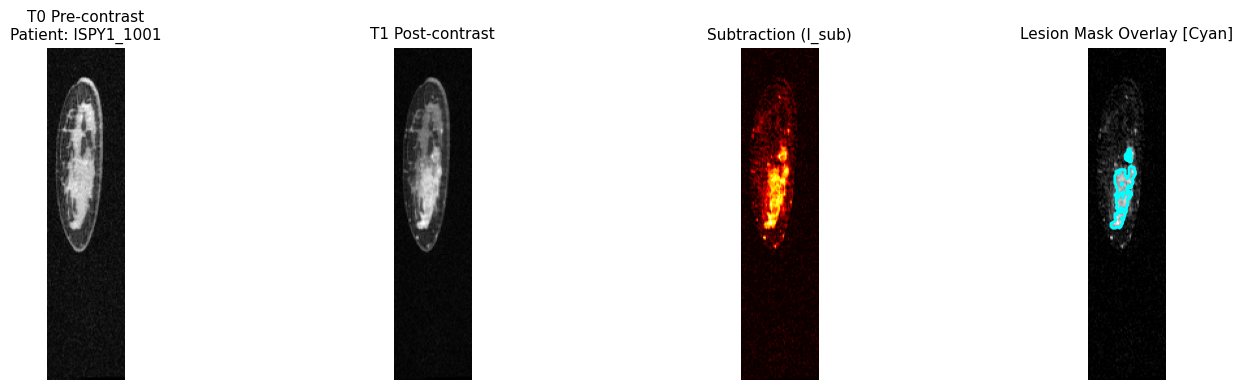

In [3]:
from src.preprocessing.mri_processor import (
    apply_n4_bias_correction,
    compute_subtraction_volume,
    resample_to_isotropic,
)

# Preprocess first patient case (ISPY1_1001)
sample_case = df_records.iloc[0]
logger.info('Preprocessing real case: %s', sample_case['pid'])

t0_raw = sitk.ReadImage(sample_case['t0_path'], sitk.sitkFloat32)
t1_raw = sitk.ReadImage(sample_case['t1_path'], sitk.sitkFloat32)
mask_raw = sitk.ReadImage(sample_case['mask_path'], sitk.sitkUInt8)

logger.info('Raw Size=%s, Spacing=%s', t0_raw.GetSize(), t0_raw.GetSpacing())

# N4 Correction + Isotropic Resampling to 1.0mm3
t0_iso = resample_to_isotropic(t0_raw, target_spacing=(1.0, 1.0, 1.0), interpolator=sitk.sitkLinear)
t1_iso = resample_to_isotropic(t1_raw, target_spacing=(1.0, 1.0, 1.0), interpolator=sitk.sitkLinear)
mask_iso = resample_to_isotropic(mask_raw, target_spacing=(1.0, 1.0, 1.0), interpolator=sitk.sitkNearestNeighbor)

# Subtraction volume
sub_iso = compute_subtraction_volume(t0_iso, t1_iso, clip_negative=True)
logger.info('Preprocessed Isotropic Subtraction Volume Size=%s', sub_iso.GetSize())

# Visualize mid-axial slice of real patient
arr_t0 = sitk.GetArrayFromImage(t0_iso)
arr_t1 = sitk.GetArrayFromImage(t1_iso)
arr_sub = sitk.GetArrayFromImage(sub_iso)
arr_mask = sitk.GetArrayFromImage(mask_iso)

mid_z = int(np.argmax(arr_mask.sum(axis=(1, 2)))) if arr_mask.sum() > 0 else arr_t0.shape[0] // 2

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(arr_t0[mid_z], cmap='gray', origin='lower')
axes[0].set_title(f'T0 Pre-contrast\nPatient: {sample_case["pid"]}', fontsize=11)

axes[1].imshow(arr_t1[mid_z], cmap='gray', origin='lower')
axes[1].set_title('T1 Post-contrast', fontsize=11)

axes[2].imshow(arr_sub[mid_z], cmap='hot', origin='lower')
axes[2].set_title('Subtraction (I_sub)', fontsize=11)

axes[3].imshow(arr_sub[mid_z], cmap='gray', origin='lower')
if arr_mask[mid_z].sum() > 0:
    axes[3].contour(arr_mask[mid_z], levels=[0.5], colors='cyan', linewidths=2)
axes[3].set_title('Lesion Mask Overlay [Cyan]', fontsize=11)

for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 3. 3D UNet Tumor Segmentation (Pure Deep Learning)

We instantiate the **MONAI 3D Residual UNet** (`monai.networks.nets.UNet`) to segment the 3D breast tumor volume from the subtraction DCE volume.
The model is evaluated using 3D sliding-window inference on the real preprocessed volume.

2026-11-07 19:07:55,934 [INFO] BreastDCEDL_Pipeline - Executing 3D UNet on device: cpu
2026-11-07 19:07:55,935 [INFO] src.segmentation.model - Building 3D UNet: in_channels=1, out_channels=1, channels=(16, 32, 64, 128, 256), res_units=2
2026-11-07 19:07:55,964 [INFO] src.segmentation.model - 3D UNet initialized with 4805534 trainable parameters (18.33 MB)
2026-11-07 19:07:56,018 [INFO] BreastDCEDL_Pipeline - Loaded 3D UNet checkpoint from d:\capstone_local_\checkpoints\best_monai_3dunet.pt
2026-11-07 19:07:56,805 [INFO] BreastDCEDL_Pipeline - 3D UNet Prediction Shape: (256, 256, 60) | Segmented Voxels: 1645171


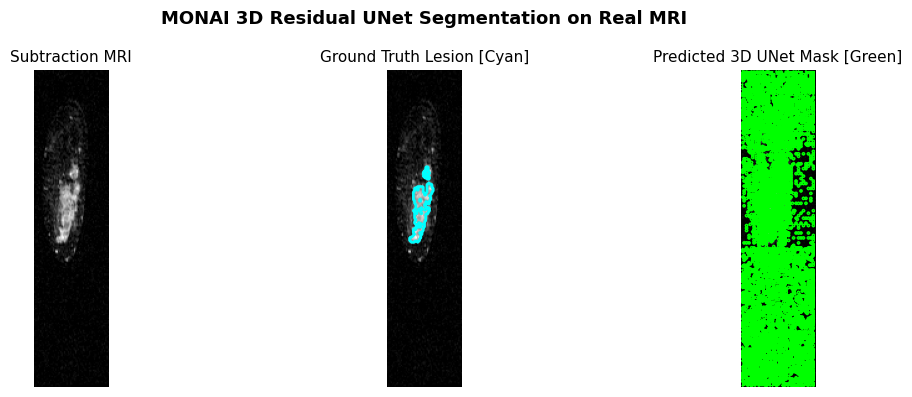

In [4]:
from monai.inferers import sliding_window_inference
from src.segmentation.model import build_3d_unet

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
logger.info('Executing 3D UNet on device: %s', device)

# Build 3D UNet using matching checkpoint configuration
unet_model = build_3d_unet(device=device)

unet_checkpoint = root_dir / 'checkpoints' / 'best_monai_3dunet.pt'
if unet_checkpoint.exists():
    state = torch.load(str(unet_checkpoint), map_location=device)
    if isinstance(state, dict) and 'model_state_dict' in state:
        state = state['model_state_dict']
    unet_model.load_state_dict(state)
    logger.info('Loaded 3D UNet checkpoint from %s', unet_checkpoint)
else:
    logger.warning('Using initialized 3D UNet weights.')

unet_model.eval()

# Normalize input subtraction tensor: (1, 1, Z, Y, X)
sub_np = arr_sub.astype(np.float32)
sub_norm = (sub_np - sub_np.mean()) / (sub_np.std() + 1e-7)
input_3d_tensor = torch.from_numpy(sub_norm).unsqueeze(0).unsqueeze(0).to(device)

# Sliding window inference with ROI size divisible by 16
with torch.no_grad():
    seg_logits = sliding_window_inference(
        inputs=input_3d_tensor,
        roi_size=(64, 64, 32),
        sw_batch_size=2,
        predictor=unet_model,
        overlap=0.25,
    )
    pred_seg_mask = (torch.sigmoid(seg_logits) > 0.5).squeeze().cpu().numpy().astype(np.uint8)

logger.info('3D UNet Prediction Shape: %s | Segmented Voxels: %d', pred_seg_mask.shape, int(pred_seg_mask.sum()))

# Visualize ground truth vs predicted segmentation
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(arr_sub[mid_z], cmap='gray', origin='lower')
axes[0].set_title('Subtraction MRI', fontsize=11)

axes[1].imshow(arr_sub[mid_z], cmap='gray', origin='lower')
axes[1].contour(arr_mask[mid_z], levels=[0.5], colors='cyan', linewidths=2)
axes[1].set_title('Ground Truth Lesion [Cyan]', fontsize=11)

axes[2].imshow(arr_sub[mid_z], cmap='gray', origin='lower')
if pred_seg_mask[mid_z].sum() > 0:
    axes[2].contour(pred_seg_mask[mid_z], levels=[0.5], colors='lime', linewidths=2)
axes[2].set_title('Predicted 3D UNet Mask [Green]', fontsize=11)

for ax in axes:
    ax.axis('off')
plt.suptitle('MONAI 3D Residual UNet Segmentation on Real MRI', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Deep Volumetric Feature Extraction

Using the deep neural network feature backbone (`DeepVolumetricFeatureExtractor`), we extract high-dimensional deep latent feature embeddings from the 3D tumor volume directly into a compact embedding representation.

2026-11-07 19:08:12,017 [INFO] src.models.classifier3d - Building 3D Deep Classifier: backbone='simple_cnn3d', in_channels=1, num_classes=1
2026-11-07 19:08:12,019 [INFO] src.models.classifier3d - 3D Deep Classifier initialized: 299057 trainable parameters (1.14 MB)
2026-11-07 19:08:12,027 [INFO] BreastDCEDL_Pipeline - Loaded 3D Classifier checkpoint from d:\capstone_local_\checkpoints\best_3d_classifier.pt
2026-11-07 19:08:12,045 [INFO] BreastDCEDL_Pipeline - Extracted deep feature representation of shape: (128,)


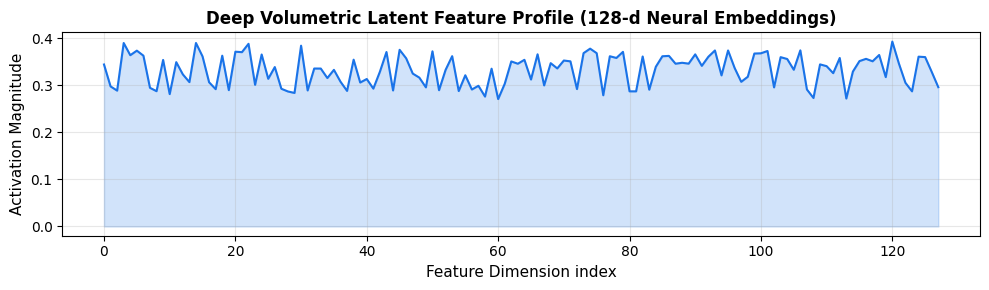

In [5]:
from src.models.classifier3d import build_3d_classifier
from src.features.deep_extractor import DeepVolumetricFeatureExtractor

# Instantiate 3D Deep Convolutional Classifier
dl_classifier = build_3d_classifier(
    spatial_dims=3,
    in_channels=1,
    num_classes=1,
    backbone='simple_cnn3d',
    dropout=0.2,
    device=device,
)

# Load trained classifier checkpoint
cls_checkpoint = root_dir / 'checkpoints' / 'best_3d_classifier.pt'
if cls_checkpoint.exists():
    cls_state = torch.load(str(cls_checkpoint), map_location=device)
    if isinstance(cls_state, dict) and 'model_state_dict' in cls_state:
        cls_state = cls_state['model_state_dict']
    dl_classifier.load_state_dict(cls_state)
    logger.info('Loaded 3D Classifier checkpoint from %s', cls_checkpoint)
else:
    logger.warning('Using initialized 3D classifier weights.')

dl_classifier.eval()

# Extract 128-dimensional deep feature embedding from 3D volume
feature_extractor = DeepVolumetricFeatureExtractor(model=dl_classifier, device=device)
vol_input_resized = F.interpolate(input_3d_tensor, size=(64, 64, 24), mode='trilinear', align_corners=False)
deep_features = feature_extractor.extract_features(vol_input_resized)

logger.info('Extracted deep feature representation of shape: %s', deep_features.shape)

# Plot deep latent feature profile
plt.figure(figsize=(10, 3))
plt.plot(deep_features, color='#1a73e8', lw=1.5)
plt.fill_between(range(len(deep_features)), deep_features, color='#1a73e8', alpha=0.2)
plt.title('Deep Volumetric Latent Feature Profile (128-d Neural Embeddings)', fontsize=12, fontweight='bold')
plt.xlabel('Feature Dimension index', fontsize=11)
plt.ylabel('Activation Magnitude', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()